## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [Alex Tan]

**Date:** [10/14/2026]

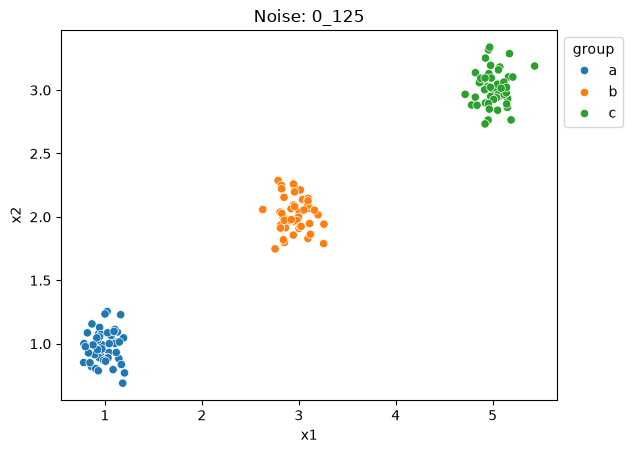

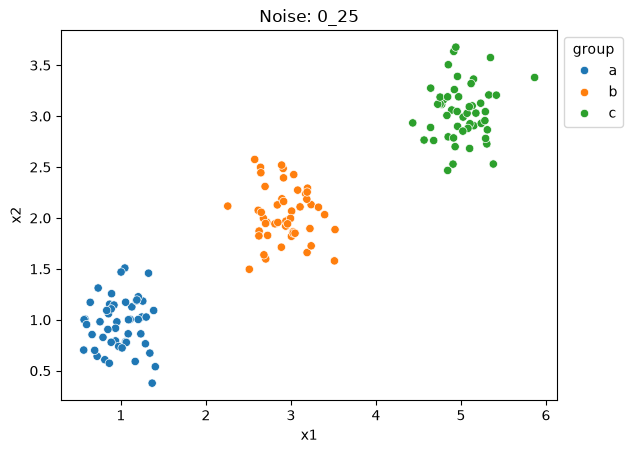

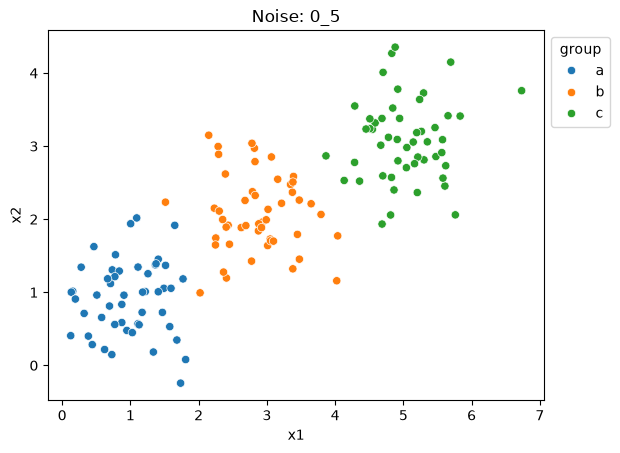

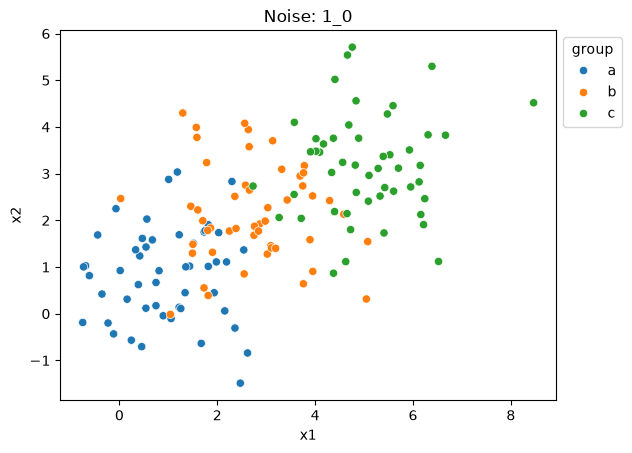

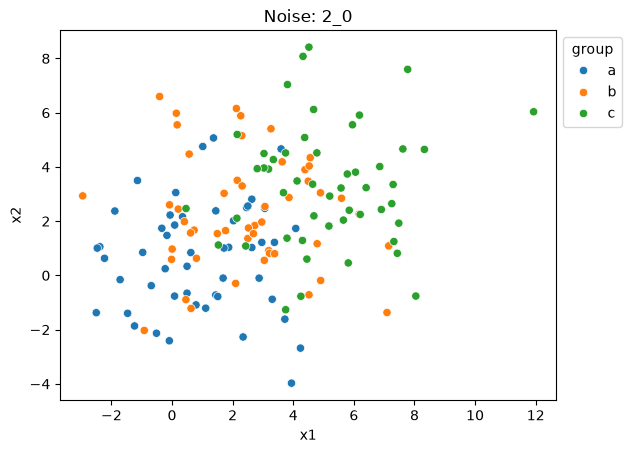

As noise goes up, the distinctness of the clusters scatter/becomes less clear. 




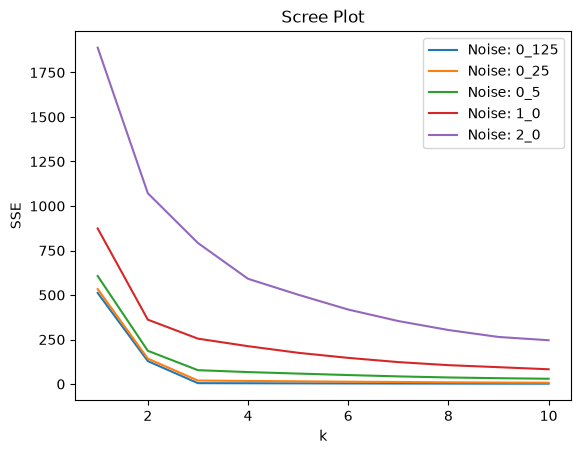

I notice how The higher the noise level, the less the elbow bends (the elbow is less clear). It will eventually become less obvious to identify elbows as noise level goes up, making it harder to identify the k values. 


Elbows allow for us to spot optimal k values more easily. The elbow marks the exact point where adding more clusters stops showing significant results.


In [3]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# 1
def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)


# Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. 
# As the `noise` goes up from 0.125 to 2.0, what happens to the visual 
# distinctness of the clusters?
ax_125 = sns.scatterplot(data=df0_125, x="x1", y="x2", hue="group")
sns.move_legend(ax_125, "upper left", bbox_to_anchor=(1, 1))
plt.title('Noise: 0_125')
plt.show()

ax_25 = sns.scatterplot(data=df0_25, x="x1", y="x2", hue="group")
sns.move_legend(ax_25, "upper left", bbox_to_anchor=(1, 1))
plt.title('Noise: 0_25')
plt.show()

ax_5 = sns.scatterplot(data=df0_5, x="x1", y="x2", hue="group")
sns.move_legend(ax_5, "upper left", bbox_to_anchor=(1, 1))
plt.title('Noise: 0_5')
plt.show()

ax1 = sns.scatterplot(data=df1_0, x="x1", y="x2", hue="group")
sns.move_legend(ax1, "upper left", bbox_to_anchor=(1, 1))
plt.title('Noise: 1_0')
plt.show()

ax2 = sns.scatterplot(data=df2_0, x="x1", y="x2", hue="group")
sns.move_legend(ax2, "upper left", bbox_to_anchor=(1, 1))
plt.title('Noise: 2_0')
plt.show()

print('As noise goes up, the distinctness of the clusters scatter/becomes less clear. \n\n')



# 3. Create a scree plot for each of the datasets. 
# Describe how the level of `noise` affects the scree plot 
# (particularly the presence of a clear "elbow") and your 
# ability to definitively select a $k$. (Pay attention to 
# the vertical axis across plots, or put all the scree curves 
# on a single canvas.)

from sklearn.cluster import KMeans

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_125[['x1', 'x2']]).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label='Noise: 0_125')

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_25[['x1', 'x2']]).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label='Noise: 0_25')

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_5[['x1', 'x2']]).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label='Noise: 0_5')

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df1_0[['x1', 'x2']]).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label='Noise: 1_0')

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df2_0[['x1', 'x2']]).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label='Noise: 2_0')
plt.title("Scree Plot")
plt.xlabel('k')
plt.ylabel('SSE')
plt.legend()
plt.show()
print('I notice how The higher the noise level, the less the elbow bends'
      ' (the elbow is less clear). It will eventually become less obvious'
      ' to identify elbows as noise level goes up, making it harder to'
      ' identify the k values. \n\n')

# 4. Explain the intuition of the elbow, using this numerical 
# simulation as an example.
print('Elbows allow for us to spot optimal k values more easily.'
      ' The elbow marks the exact point where adding more clusters'
      ' stops showing significant results.')

No further cleaning of variables is required


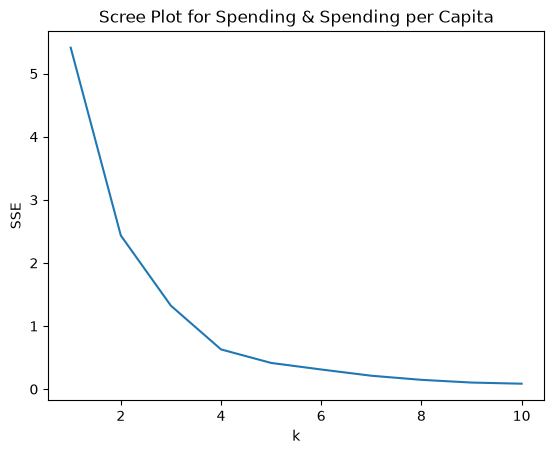

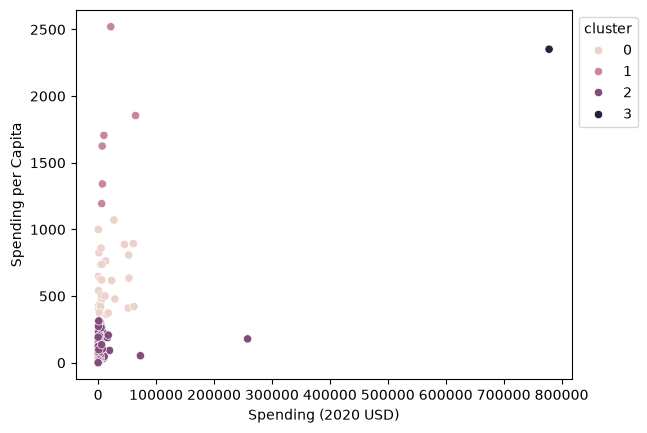

         index                                                            \
         count         mean          std     min     25%     50%     75%   
cluster                                                                    
0         30.0  2782.600000  1664.320688   236.0  1494.0  2769.0  4307.5   
1          6.0  3783.333333   843.766476  2582.0  3194.0  4027.0  4375.5   
2        111.0  2768.540541  1665.488123    32.0  1205.0  2752.0  4112.0   
3          1.0  5540.000000          NaN  5540.0  5540.0  5540.0  5540.0   

                  Year          ... Percent of Government Spending            \
            max  count    mean  ...                            75%       max   
cluster                         ...                                            
0        5506.0   30.0  2020.0  ...                       0.048819  0.114776   
1        4656.0    6.0  2020.0  ...                       0.164503  0.225050   
2        5880.0  111.0  2020.0  ...                       0.083508 

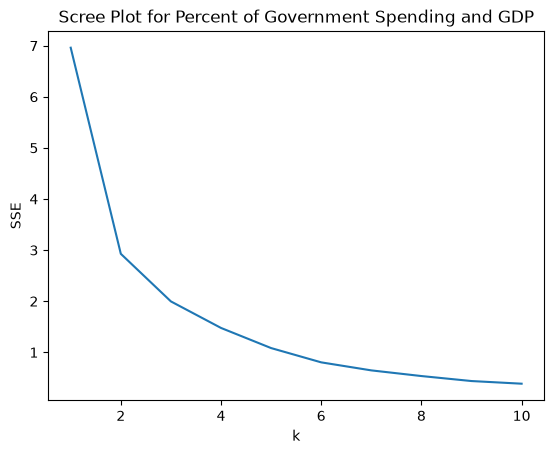

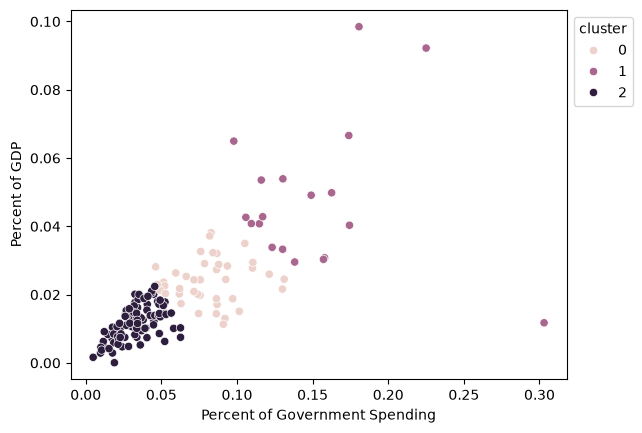

        index                                                           \
        count         mean          std    min     25%     50%     75%   
cluster                                                                  
0        40.0  3046.100000  1761.744703  134.0  1604.5  2939.0  4843.0   
1        19.0  2272.421053  1631.208629  100.0   542.0  2718.0  3670.0   
2        89.0  2854.000000  1600.882796   32.0  1562.0  2888.0  4180.0   

                 Year          ... Percent of Government Spending            \
            max count    mean  ...                            75%       max   
cluster                        ...                                            
0        5574.0  40.0  2020.0  ...                       0.092176  0.131184   
1        4486.0  19.0  2020.0  ...                       0.168248  0.303027   
2        5880.0  89.0  2020.0  ...                       0.043645  0.062685   

        Spending per Capita                                                \
   

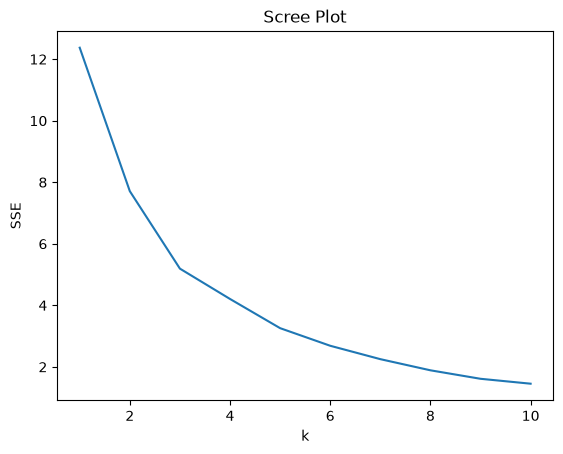

        index                                                           \
        count         mean          std    min     25%     50%     75%   
cluster                                                                  
0        40.0  3046.100000  1761.744703  134.0  1604.5  2939.0  4843.0   
1        19.0  2272.421053  1631.208629  100.0   542.0  2718.0  3670.0   
2        89.0  2854.000000  1600.882796   32.0  1562.0  2888.0  4180.0   

                 Year          ... Percent of Government Spending            \
            max count    mean  ...                            75%       max   
cluster                        ...                                            
0        5574.0  40.0  2020.0  ...                       0.092176  0.131184   
1        4486.0  19.0  2020.0  ...                       0.168248  0.303027   
2        5880.0  89.0  2020.0  ...                       0.043645  0.062685   

        Spending per Capita                                                \
   

In [4]:
# 1. Load the `SIPRI Military Expenditure Database.csv` file in 
# the `./data` folder. This has data about military spending by 
# country. Filter the rows to select only the year 2020, and drop \
# all rows with missing values. I ended up with 148 countries. 
# Is any further cleaning of the variables required?

df = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')
# set year to 2020
df2020 = df[df['Year'] == 2020]
# drop missing vlaues
df2020 = df2020.dropna()
# df2020.count()    # count number of values left for each category
print('No further cleaning of variables is required')


# 2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. 
# Use a scree plot to determine the optimal number of clusters for the 
# $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` 
# and `Spending per Capita`, and hue the dots by their cluster membership. 
# Compute a describe table conditional on cluster membership 
# (i.e. `.groupby(cluster).describe()`). What do you see? Where is the 
# United States? Do you notice any patterns in the cluster membership?


from sklearn.preprocessing import MinMaxScaler

# normalize
mms = MinMaxScaler()
spending_scaled = mms.fit_transform(df2020[['Spending (2020 USD)', 'Spending per Capita']])

# scree plot
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(spending_scaled).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title='Scree Plot for Spending & Spending per Capita', xlabel='k', ylabel='SSE')
plt.show()

# scatterplot
model = KMeans(n_clusters=4, n_init="auto", random_state=0).fit(spending_scaled)
df2020["cluster"] = model.labels_

ax = sns.scatterplot(data=df2020, x="Spending (2020 USD)", y="Spending per Capita", hue="cluster")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.show()

# Describe table
print(df2020.groupby('cluster').describe())
print(df2020.groupby('cluster')['Country'].apply(list))
print(df2020.loc[df['Country'].str.contains("United States"), ['Country', 'cluster']])

print('\nThe optimal k value is 4 based on the elbow point. The United States forms its ' \
'own cluster due to its high spending compared to all other nations. Overall, the clusters ' \
'group countries by spending levels, with larger groups for lower spenders and smaller ' \
'groups for higher spenders. Each cluster has a similar mean')

# 3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. 
# How do your results compare to part 2?

# normalize
mms = MinMaxScaler()
percent_scaled = mms.fit_transform(df2020[['Percent of Government Spending', 'Percent of GDP']])

# scree plot
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(percent_scaled).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title='Scree Plot for Percent of Government Spending and GDP', xlabel='k', ylabel='SSE')
plt.show()

# scatterplot
model = KMeans(n_clusters=3, n_init="auto", random_state=0).fit(percent_scaled)
df2020["cluster"] = model.labels_

ax = sns.scatterplot(data=df2020, x="Percent of Government Spending", y="Percent of GDP", hue="cluster")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.show()

# Describe table
print(df2020.groupby('cluster').describe())
print(df2020.groupby('cluster')['Country'].apply(list))
print(df2020.loc[df['Country'].str.contains("United States"), ['Country', 'cluster']])

print('\nThe optimal k value is 3 based on the elbow. The United States is in cluster 0 this ' \
'time and has an average percent of government spending and GDP. Overall, the clusters ' \
'group countries by percent levels, with larger groups for lower spenders and smaller ' \
'groups for higher spenders.')


# 4. Use $k$ means clustering with all four numeric variables: 
# `Spending (2020 USD)`, `Spending per Capita`, 
# `Percent of Government Spending`, and `Percent of GDP`. 
# How do your results compare to the previous two parts? 

# normalize
mms = MinMaxScaler()
scaled = mms.fit_transform(df2020[['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']])

# scree plot
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(scaled).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title='Scree Plot', xlabel='k', ylabel='SSE')
plt.show()

# Describe table
print(df2020.groupby('cluster').describe())
print(df2020.groupby('cluster')['Country'].apply(list))
print(df2020.loc[df['Country'].str.contains("United States"), ['Country', 'cluster']])

print('\nI notice that the optimal k value (=5) for this plot is higher than the previous 2 parts. ' \
      'The scree plot here looks really similar to the percent scree plot (second part). The US '
      'is also not in its own cluster, unlike in the first part. ')

# 5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?
print('\n\nYes, k-means clustering successfully identified key patterns by separating absolute spending '
      'outliers like the U.S. from other nations, while also revealing distinct groupings based on '
      'national fiscal priorities like percentage of GDP.')

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [5]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]